# **SAAS CUSTOMER CHURN INTELLIGENCE**

In [3]:
# importation of library
import pandas as pd # library for data cleaning, transformation, analysis
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
path = r"C:\Users\DELL\AppData\Local\Packages\5319275A.51895FA4EA97F_cv1g1gvanyjgm\LocalState\sessions\A4FBEE0BA22652FDEC4DAAEA7C9B75A62777DE24\transfers\2026-42\MP_Synthetics_50000_Rows.csv"

In [5]:
df = pd.read_csv(path)

In [6]:
print(df)

      Customer_ID        Company_Name       Industry    Country Company_Size  \
0       CUST-1001       Pulse Net 944     HealthTech  Australia        11-50   
1       CUST-1002     Pulse Logic 332  CyberSecurity        USA       51-200   
2       CUST-1003     Secure Flow 975       DevTools      India         1-10   
3       CUST-1004   Quantum Scale 657         EdTech  Singapore       51-200   
4       CUST-1005  Quantum Sphere 308     E-Commerce    Germany         1-10   
...           ...                 ...            ...        ...          ...   
49995  CUST-50996         Omni AI 147  CyberSecurity     Canada         1-10   
49996  CUST-50997      Vibe Logic 456        MarTech      India         1-10   
49997  CUST-50998     Quantum Net 553        FinTech         UK         1-10   
49998  CUST-50999      Pulse Flow 109        FinTech     France         1-10   
49999  CUST-51000       Vibe Tech 139      Logistics     Canada       51-200   

      Account_Manager Plan_Tier Billing

In [18]:
df.columns = df.columns.str.lower() # change the column names to lower case
df.columns
df.columns = df.columns.str.strip()  # revove extra spacing
df.columns

Index(['customer_id', 'company_name', 'industry', 'country', 'company_size',
       'account_manager', 'plan_tier', 'billing_cycle',
       'monthly_recurring_revenue', 'signup_date', 'last_active_date',
       'payment_status', 'active_seats_used', 'total_seats_allowed',
       'support_tickets_30d', 'feature_adoption_rate', 'churn_risk_score',
       'is_churned'],
      dtype='str')

In [21]:
df.duplicated().any()  # check if there is any duplicated rows
df.duplicated().sum() # count the number of duplicated rows
df.isna().any() # check for null entries

customer_id                  False
company_name                 False
industry                     False
country                      False
company_size                 False
account_manager              False
plan_tier                    False
billing_cycle                False
monthly_recurring_revenue    False
signup_date                  False
last_active_date             False
payment_status               False
active_seats_used            False
total_seats_allowed          False
support_tickets_30d          False
feature_adoption_rate        False
churn_risk_score             False
is_churned                   False
dtype: bool

In [10]:
df.shape # count the no of rows and columns

(50000, 18)

In [20]:
 df.head()

,customer_id,company_name,industry,country,company_size,account_manager,plan_tier,billing_cycle,monthly_recurring_revenue,signup_date,last_active_date,payment_status,active_seats_used,total_seats_allowed,support_tickets_30d,feature_adoption_rate,churn_risk_score,is_churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   customer_id                50000 non-null  str  
 1   company_name               50000 non-null  str  
 2   industry                   50000 non-null  str  
 3   country                    50000 non-null  str  
 4   company_size               50000 non-null  str  
 5   account_manager            50000 non-null  str  
 6   plan_tier                  50000 non-null  str  
 7   billing_cycle              50000 non-null  str  
 8   monthly_recurring_revenue  50000 non-null  int64
 9   signup_date                50000 non-null  str  
 10  last_active_date           50000 non-null  str  
 11  payment_status             50000 non-null  str  
 12  active_seats_used          50000 non-null  int64
 13  total_seats_allowed        50000 non-null  int64
 14  support_tickets_30d        50000 

In [22]:
# convertng the data type of date coulumn to date type
df["signup_date"] = pd.to_datetime(df["signup_date"],format = "%Y-%m-%d")

In [27]:
df.info()  # checking 

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   customer_id                50000 non-null  str           
 1   company_name               50000 non-null  str           
 2   industry                   50000 non-null  str           
 3   country                    50000 non-null  str           
 4   company_size               50000 non-null  str           
 5   account_manager            50000 non-null  str           
 6   plan_tier                  50000 non-null  str           
 7   billing_cycle              50000 non-null  str           
 8   monthly_recurring_revenue  50000 non-null  int64         
 9   signup_date                50000 non-null  datetime64[us]
 10  last_active_date           50000 non-null  datetime64[us]
 11  payment_status             50000 non-null  str           
 12  active_seats_us

In [26]:
df["last_active_date"] = pd.to_datetime(df["last_active_date"],format = "%Y-%m-%d")

In [28]:
df.nunique() # check for the no of unique values in each columns

customer_id                  50000
company_name                 38437
industry                         8
country                          8
company_size                     6
account_manager                  5
plan_tier                        3
billing_cycle                    2
monthly_recurring_revenue     3648
signup_date                   1170
last_active_date               164
payment_status                   3
active_seats_used              897
total_seats_allowed            897
support_tickets_30d              9
feature_adoption_rate           71
churn_risk_score                 3
is_churned                       2
dtype: int64

In [33]:
df["is_churned"].unique() # check the unique values in is churned columns

array(['not_churned', 'churned'], dtype=object)

In [32]:
# changing 1 to churned and 0 to not churned
df["is_churned"] = df["is_churned"].replace({1:"churned",0:"not_churned"})

In [35]:
df["is_churned"].value_counts() # counting the no of churned and not churned

is_churned
not_churned    49084
churned          916
Name: count, dtype: int64

In [37]:
df.describe().T # checking the descriptive statistics of the data

,count,mean,min,25%,50%,75%,max,std
monthly_recurring_revenue,50000.0,665.35816,49.0,79.0,129.0,299.0,8499.0,1592.411168
signup_date,50000,2024-06-26 19:23:24.288000,2022-11-17 00:00:00,2023-09-10 00:00:00,2024-06-27 00:00:00,2025-04-16 00:00:00,2026-01-29 00:00:00,NaN
last_active_date,50000,2026-02-19 17:52:42.815999,2025-09-02 00:00:00,2026-02-18 00:00:00,2026-02-21 00:00:00,2026-02-25 00:00:00,2026-02-28 00:00:00,NaN
active_seats_used,50000.0,50.84396,1.0,3.0,6.0,26.0,976.0,133.757042
total_seats_allowed,50000.0,73.66436,3.0,6.0,9.0,39.0,999.0,185.526556
support_tickets_30d,50000.0,3.35136,0.0,2.0,3.0,5.0,8.0,1.681904


In [38]:
churned_data = df[df["is_churned"] == "churned"]

In [39]:
churned_data

,customer_id,company_name,industry,country,company_size,account_manager,plan_tier,billing_cycle,monthly_recurring_revenue,signup_date,last_active_date,payment_status,active_seats_used,total_seats_allowed,support_tickets_30d,feature_adoption_rate,churn_risk_score,is_churned
116,CUST-1117,Quantum Tech 557,EdTech,India,11-50,Aisha Khan,Starter,Monthly,99,2025-08-25,2025-11-02,Pending,3,5,5,62%,Low,churned
131,CUST-1132,Cloud Metrics 275,MarTech,Germany,1-10,Elena Rostova,Starter,Monthly,79,2025-06-02,2025-11-29,Failed,4,9,6,50%,Medium,churned
197,CUST-1198,Data Tech 683,E-Commerce,USA,51-200,Elena Rostova,Pro,Monthly,299,2023-12-05,2025-10-24,Failed,18,40,6,42%,Medium,churned
201,CUST-1202,Vibe Scale 531,DevTools,Australia,201-500,Marcus Vance,Pro,Annual,499,2023-12-19,2026-01-15,Pending,17,40,5,34%,Low,churned
211,CUST-1212,Nexus Labs 264,MarTech,Germany,201-500,Marcus Vance,Pro,Annual,399,2024-07-03,2026-01-29,Active,28,54,5,58%,Low,churned
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49505,CUST-50506,Nexus Metrics 457,Logistics,Canada,1-10,Sarah Jenkins,Starter,Monthly,129,2025-04-09,2026-01-10,Failed,6,9,5,69%,Low,churned
49645,CUST-50646,Vibe Sphere 448,MarTech,France,51-200,Marcus Vance,Pro,Monthly,399,2023-07-20,2025-10-17,Active,17,42,6,38%,Low,churned
49737,CUST-50738,Pulse Flow 956,DevTools,Germany,1-10,Marcus Vance,Starter,Annual,129,2024-05-09,2025-09-24,Active,5,9,6,60%,Low,churned
49779,CUST-50780,Vibe Net 599,HealthTech,UK,1-10,Elena Rostova,Starter,Monthly,129,2024-01-28,2025-12-18,Active,2,6,4,36%,Low,churned


In [40]:
churned_data.describe().T  # checking the descriptive statistics of the churned data

,count,mean,min,25%,50%,75%,max,std
monthly_recurring_revenue,916.0,432.358079,49.0,79.0,99.0,249.0,8241.0,1249.103372
signup_date,916,2024-06-27 06:51:52.663755,2022-11-18 00:00:00,2023-10-01 00:00:00,2024-06-14 00:00:00,2025-04-29 06:00:00,2026-01-29 00:00:00,NaN
last_active_date,916,2025-11-16 07:24:53.449781,2025-09-02 00:00:00,2025-10-09 00:00:00,2025-11-19 00:00:00,2025-12-23 00:00:00,2026-01-29 00:00:00,NaN
active_seats_used,916.0,24.793668,1.0,2.0,3.0,9.0,731.0,80.563467
total_seats_allowed,916.0,46.507642,3.0,5.0,7.0,21.0,992.0,144.769774
support_tickets_30d,916.0,4.973799,0.0,4.0,5.0,6.0,8.0,1.432401


In [43]:
churned_data["company_name"].nunique() # checking the no of churned companies

911

In [65]:
industry_count = churned_data.groupby("industry").agg(industry_count = ("industry","count")).sort_values(by = "industry_count" ,ascending = False).reset_index().head()

In [66]:
industry_count

,industry,industry_count
0,EdTech,128
1,DevTools,121
2,Logistics,119
3,MarTech,113
4,CyberSecurity,112


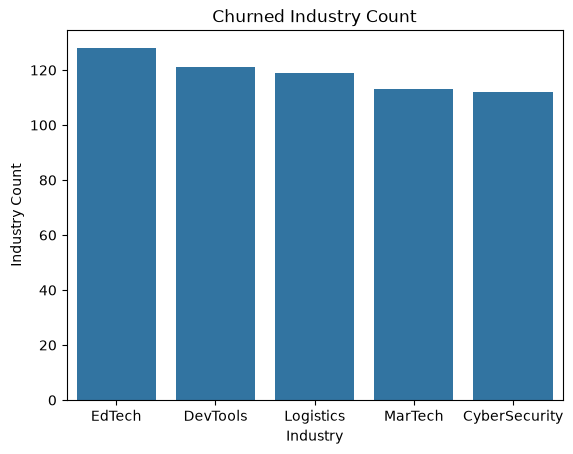

In [68]:
sns.barplot(data = industry_count,x = "industry", y = "industry_count")
plt.title("Churned Industry Count")
plt.xlabel("Industry")
plt.ylabel("Industry Count")
plt.show()

### **Customer Churn Analysis by Industry**
The analysis shows that EdTech has the highest customer churn count, with 128 customers, followed by DevTools with 121 and Logistics with 119. MarTech recorded 113 churned customers, while CyberSecurity had the lowest count at 112.

These results suggest that businesses in the EdTech industry may need to focus more on customer retention strategies. However, further analysis of churn rates is necessary to determine which industry loses the highest proportion of its customers.

In [69]:
popular_sub_tier = churned_data.groupby("plan_tier").agg(plan_tier_count = ("plan_tier","count"))

In [72]:
popular_sub_tier

,plan_tier_count
plan_tier,
Enterprise,57
Pro,174
Starter,685


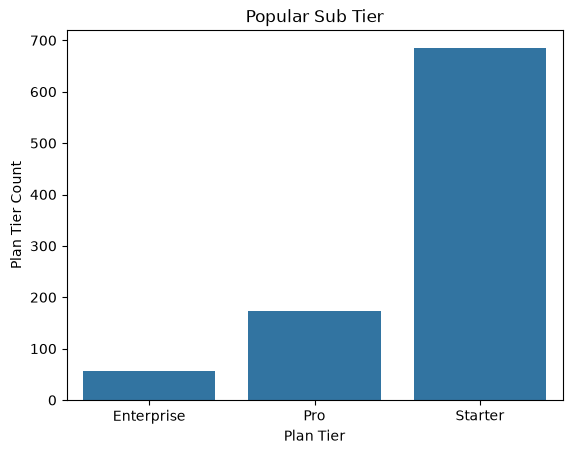

In [71]:
sns.barplot(data = popular_sub_tier , x = "plan_tier" , y = "plan_tier_count")
plt.title("Popular Sub Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Plan Tier Count")
plt.show()

### **Customer Churn Analysis by Plan Tier**
The analysis shows that the Starter plan has the highest churn count, with 685 customers, followed by the Pro plan with 174 customers and the Enterprise plan with 57 customers.

This suggests that the Starter plan accounts for the largest number of churned customers. Businesses should investigate why Starter users are leaving and consider improving customer support, engagement, and plan benefits. However, comparing churn rates across the three plans is necessary to determine which tier has the highest proportion of customers leaving.

In [73]:
payment_status_count = churned_data.groupby("payment_status").agg(payment_status_count = ("payment_status","count")).sort_values(by = "payment_status_count" ,ascending = False).reset_index()

In [74]:
payment_status_count 

,payment_status,payment_status_count
0,Active,513
1,Failed,294
2,Pending,109


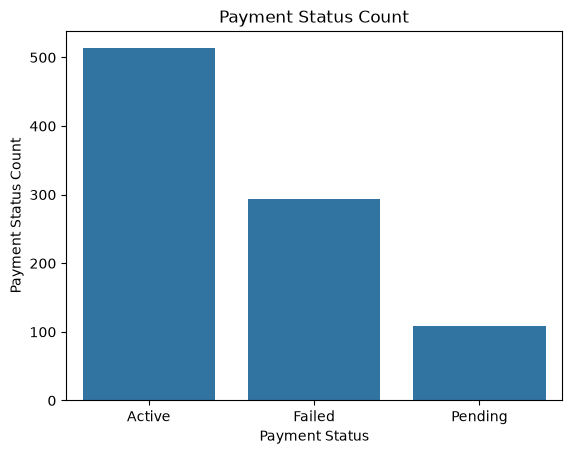

In [75]:
sns.barplot(data = payment_status_count  , x = "payment_status" , y = "payment_status_count")
plt.title("Payment Status Count")
plt.xlabel("Payment Status")
plt.ylabel("Payment Status Count")
plt.show()

In [77]:
churned_data["feature_adoption_rate"].unique()

<StringArray>
[ '62%',  '50%',  '42%',  '34%',  '58%',  '43%',  '72%',  '38%',  '56%',
  '45%',  '66%',  '49%',  '48%',  '55%',  '39%',  '85%',  '37%',  '54%',
  '59%',  '47%',  '77%',  '44%',  '51%',  '35%',  '32%',  '41%',  '61%',
  '53%',  '89%',  '57%',  '90%',  '36%',  '84%',  '46%',  '31%',  '40%',
  '69%',  '60%',  '64%',  '87%',  '70%',  '52%',  '67%',  '33%',  '81%',
  '76%',  '75%',  '63%',  '79%',  '65%',  '73%',  '68%',  '78%', '100%',
  '74%',  '80%',  '82%',  '71%',  '88%',  '94%',  '96%',  '92%',  '83%',
  '91%',  '86%']
Length: 65, dtype: str

In [88]:
churned_data["feature_adoption_rate"] = churned_data["feature_adoption_rate"].str.replace("%", "", regex=False)
churned_data["feature_adoption_rate"]

116      62
131      50
197      42
201      34
211      58
         ..
49505    69
49645    38
49737    60
49779    36
49857    56
Name: feature_adoption_rate, Length: 916, dtype: str

In [89]:
churned_data["feature_adoption_rate"] = churned_data["feature_adoption_rate"].astype(float)

In [90]:
churned_data["feature_adoption_rate"]

116      62.0
131      50.0
197      42.0
201      34.0
211      58.0
         ... 
49505    69.0
49645    38.0
49737    60.0
49779    36.0
49857    56.0
Name: feature_adoption_rate, Length: 916, dtype: float64

In [91]:
country_count = churned_data.groupby("country").agg(country_count = ("country","count")).sort_values(by = "country_count" ,ascending = False).reset_index()

In [92]:
country_count

,country,country_count
0,Singapore,135
1,USA,126
2,France,125
3,Germany,115
4,India,112
5,Canada,109
6,Australia,99
7,UK,95


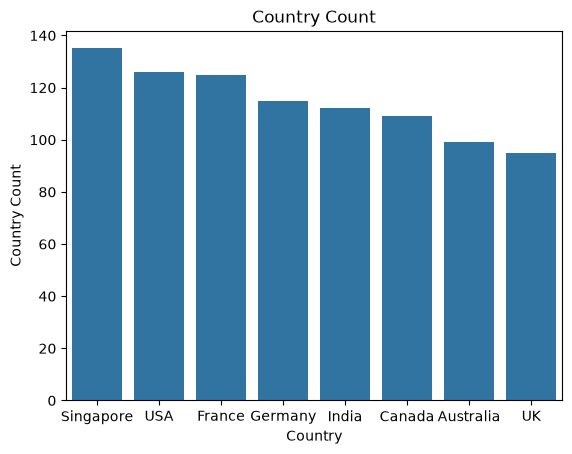

In [93]:
sns.barplot(data = country_count  , x = "country" , y = "country_count")
plt.title("Country Count")
plt.xlabel("Country")
plt.ylabel("Country Count")
plt.show()

## **Customer Distribution by Country**
The analysis shows that Singapore has the highest customer count, with 135 customers, followed by the USA with 126 and France with 125. Germany recorded 115 customers, India 112, Canada 109, and Australia 99, while the UK had the lowest count at 95.

This suggests that Singapore is the strongest market among the countries analyzed, while the UK has the lowest customer representation. The business could investigate opportunities to attract more customers in lower-count markets while maintaining growth in stronger markets. However, these figures represent customer counts, not market share or customer growth rates.

In [97]:
account_manager_count = churned_data.groupby("account_manager").agg(account_manager_count = ("account_manager","count")).sort_values(by = "account_manager" ,ascending = False).reset_index()

In [98]:
account_manager_count

,account_manager,account_manager_count
0,Sarah Jenkins,195
1,Marcus Vance,195
2,Elena Rostova,186
3,David Ross,178
4,Aisha Khan,162


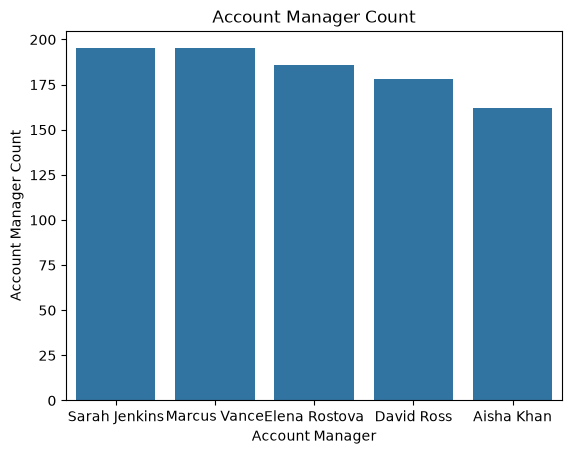

In [99]:
sns.barplot(data = account_manager_count , x = "account_manager" , y = "account_manager_count")
plt.title("Account Manager Count")
plt.xlabel("Account Manager")
plt.ylabel("Account Manager Count")
plt.show()

In [105]:
churned_data["month"]=churned_data["last_active_date"].dt.month_name()

In [106]:
churned_data["month"]

116       November
131       November
197        October
201        January
211        January
           ...    
49505      January
49645      October
49737    September
49779     December
49857      January
Name: month, Length: 916, dtype: str

In [107]:
churned_data["year"]=churned_data["last_active_date"].dt.year

In [108]:
churned_data["year"]

116      2025
131      2025
197      2025
201      2026
211      2026
         ... 
49505    2026
49645    2025
49737    2025
49779    2025
49857    2026
Name: year, Length: 916, dtype: int32

In [109]:
print(churned_data)

      customer_id       company_name    industry    country company_size  \
116     CUST-1117   Quantum Tech 557      EdTech      India        11-50   
131     CUST-1132  Cloud Metrics 275     MarTech    Germany         1-10   
197     CUST-1198      Data Tech 683  E-Commerce        USA       51-200   
201     CUST-1202     Vibe Scale 531    DevTools  Australia      201-500   
211     CUST-1212     Nexus Labs 264     MarTech    Germany      201-500   
...           ...                ...         ...        ...          ...   
49505  CUST-50506  Nexus Metrics 457   Logistics     Canada         1-10   
49645  CUST-50646    Vibe Sphere 448     MarTech     France       51-200   
49737  CUST-50738     Pulse Flow 956    DevTools    Germany         1-10   
49779  CUST-50780       Vibe Net 599  HealthTech         UK         1-10   
49857  CUST-50858      Data Flow 932   Logistics    Germany         1-10   

      account_manager plan_tier billing_cycle  monthly_recurring_revenue  \
116        

In [110]:
year_count = churned_data.groupby("year").agg(year_count = ("year","count")).sort_values(by = "year" ,ascending = False).reset_index()

In [111]:
year_count

,year,year_count
0,2026,174
1,2025,742


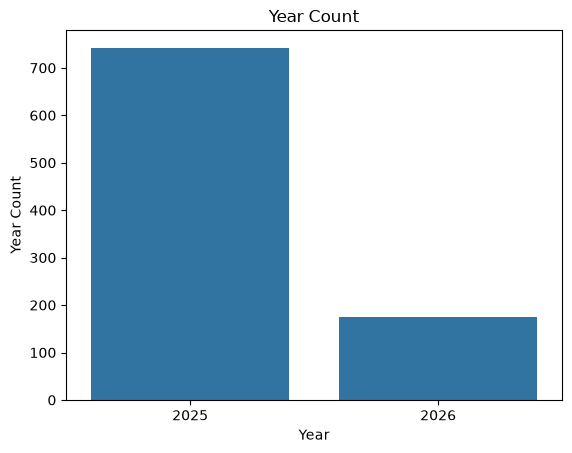

In [112]:
sns.barplot(data = year_count , x = "year" , y = "year_count")
plt.title("Year Count")
plt.xlabel("Year")
plt.ylabel("Year Count")
plt.show()

In [119]:
month_count = churned_data.groupby("month").agg(month_count = ("month","count")).sort_values(by = "month_count" ,ascending = False).reset_index()

In [120]:
month_count

,month,month_count
0,December,212
1,September,179
2,November,176
3,October,175
4,January,174


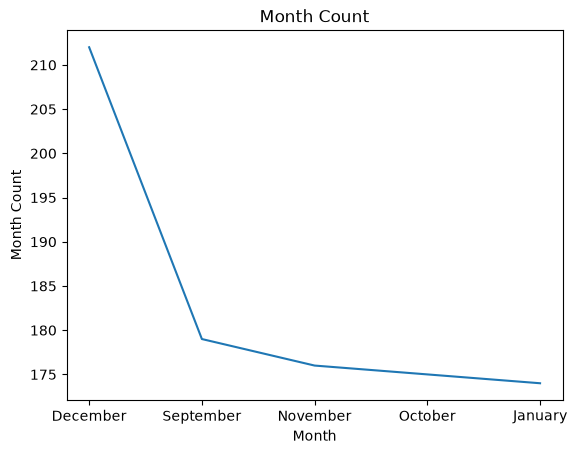

In [121]:
sns.lineplot(data = month_count , x = "month" , y = "month_count")
plt.title("Month Count")
plt.xlabel("Month")
plt.ylabel("Month Count")
plt.show()

In [ ]:
month_order = ["January","December"]
pd.Categorical(month_name)